<a href="https://colab.research.google.com/github/Ariiiiii22/MetroCDMX_DFS-y-BFS/blob/main/Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST

Fashion-MNIST usando `Flatten`, graficar la representación en 2D y comparar al menos 3 configuraciones con *accuracy* como métrica.



In [1]:
!pip install -q importlib_resources

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

In [3]:
def plot_learning_curve(history, titulo=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    # Graficar exactitud
    axes[0].plot(history.history['accuracy'], label='Training accuracy')
    axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
    axes[0].set_title(f'accuracy Curves {titulo}')
    axes[0].set_xlabel('Época')
    axes[0].legend()
    # Graficar pérdida
    axes[1].plot(history.history['loss'], label='Training Loss')
    axes[1].plot(history.history['val_loss'], label='Validation Loss')
    axes[1].set_title(f'Loss Curves {titulo}')
    axes[1].set_xlabel('Época')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [4]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)

In [5]:
os.makedirs("models", exist_ok=True)
EPOCAS = 15

## 1. Carga de datos

In [6]:
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.HBRPOI_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.HBRPOI_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.


In [7]:
clases = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
          "Sandalia", "Camisa", "Tenis", "Bolsa", "Botín"]

In [8]:
# Un lote: 32 imágenes de 28 x 28 con 1 canal (escala de grises)
for imagenes, etiquetas in train_ds.take(1):
    print("Forma del lote:", imagenes.shape, "| etiquetas:", etiquetas.shape)
    print("Intensidad mínima y máxima:", imagenes.numpy().min(), imagenes.numpy().max())

Forma del lote: (32, 28, 28, 1) | etiquetas: (32,)
Intensidad mínima y máxima: 0 255


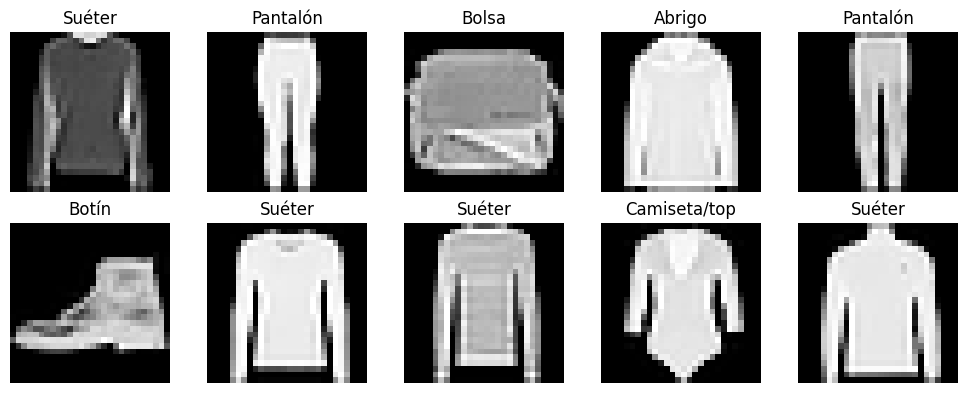

In [9]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(imagenes[i, :, :, 0], cmap="gray")
    plt.title(clases[etiquetas[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Normalización y conjunto de validación

- Dividimos entre 255 para que cada píxel quede entre 0 y 1, igual que en MNIST.
- Como en clase, partimos el conjunto de prueba (10,000 imágenes) en dos mitades: **validación** (para el `ModelCheckpoint` y las curvas) y **prueba** (solo para medir el accuracy final).

In [10]:
def normalizar(imagen, etiqueta):
    return tf.cast(imagen, tf.float32) / 255.0, etiqueta

train_ds = train_ds.map(normalizar).cache().prefetch(tf.data.AUTOTUNE)
test_full_ds = test_ds.map(normalizar).cache()

n_lotes = int(test_full_ds.cardinality())   # 313 lotes de 32
val_ds = test_full_ds.take(n_lotes // 2).prefetch(tf.data.AUTOTUNE)
test_ds = test_full_ds.skip(n_lotes // 2).prefetch(tf.data.AUTOTUNE)

print("Lotes -> train:", int(train_ds.cardinality()),
      "| val:", int(val_ds.cardinality()),
      "| test:", int(test_ds.cardinality()))

Lotes -> train: 1875 | val: 156 | test: 157


In [11]:
# Arreglos de numpy de validación y prueba para graficar y para la matriz de confusión
X_val = np.concatenate([x for x, y in val_ds])
y_val = np.concatenate([y for x, y in val_ds])
X_test = np.concatenate([x for x, y in test_ds])
y_test = np.concatenate([y for x, y in test_ds])
X_val.shape, X_test.shape

((4992, 28, 28, 1), (5008, 28, 28, 1))

`Flatten` convierte cada imagen de $28 \times 28 \times 1$ en un vector de $784$ valores. Las capas `Dense` solo reciben vectores, así que la red pierde la noción de "qué píxel está junto a cuál".

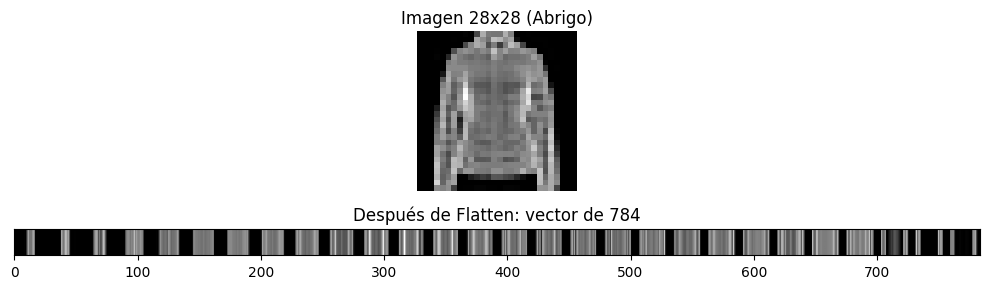

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(10, 3), gridspec_kw={"height_ratios": [6, 1]})
axes[0].imshow(X_val[0, :, :, 0], cmap="gray"); axes[0].set_title(f"Imagen 28x28 ({clases[y_val[0]]})"); axes[0].axis("off")
axes[1].imshow(X_val[0].reshape(1, 784), cmap="gray", aspect="auto"); axes[1].set_title("Después de Flatten: vector de 784"); axes[1].set_yticks([])
plt.tight_layout()
plt.show()

In [13]:
def plot_espacio_2d(model, titulo, n=3000):
    extractor = tf.keras.Model(
        inputs = model.inputs,
        outputs = model.get_layer("rep_2d").output
    )
    puntos2d = extractor.predict(X_val[:n], verbose=0)

    plt.figure(figsize=(7, 6))
    scatter_plot = plt.scatter(
        puntos2d[:, 0],
        puntos2d[:, 1],
        c=y_val[:n],
        cmap="tab10",
        s=8,
        alpha=0.75,
    )
    barra = plt.colorbar(scatter_plot, ticks=range(10))
    barra.ax.set_yticklabels(clases)
    plt.title(f"Espacio latente 2D — {titulo}")
    plt.xlabel("Neurona de representación 1")
    plt.ylabel("Neurona de representación 2")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

In [14]:
resultados = []

## Configuración 1: Una capa oculta

Igual que el *Modelo 2* de la clase: `Flatten → Dense(128, relu) → rep_2d(2) → Dense(10, softmax)`, optimizador Adam.

In [15]:
model1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])

model1.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,768 (393.62 KB)

 Trainable params: 100,768 (393.62 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
RUTA_MODELO = "models/config_1.keras"
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=RUTA_MODELO,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)

history1 = model1.fit(
    train_ds,
    epochs = EPOCAS,
    validation_data = val_ds,
    callbacks = [model_checkpoint],
    verbose = 2
)

Epoch 1/15
1875/1875 - 21s - 11ms/step - accuracy: 0.7072 - loss: 0.8654 - val_accuracy: 0.7837 - val_loss: 0.6485
Epoch 2/15
1875/1875 - 10s - 6ms/step - accuracy: 0.8184 - loss: 0.5827 - val_accuracy: 0.8247 - val_loss: 0.5519
Epoch 3/15
1875/1875 - 8s - 4ms/step - accuracy: 0.8392 - loss: 0.5059 - val_accuracy: 0.8295 - val_loss: 0.5126
Epoch 4/15
1875/1875 - 9s - 5ms/step - accuracy: 0.8504 - loss: 0.4634 - val_accuracy: 0.8391 - val_loss: 0.4959
Epoch 5/15
1875/1875 - 11s - 6ms/step - accuracy: 0.8599 - loss: 0.4332 - val_accuracy: 0.8446 - val_loss: 0.4848
Epoch 6/15
1875/1875 - 22s - 12ms/step - accuracy: 0.8677 - loss: 0.4085 - val_accuracy: 0.8452 - val_loss: 0.4771
Epoch 7/15
1875/1875 - 11s - 6ms/step - accuracy: 0.8742 - loss: 0.3876 - val_accuracy: 0.8472 - val_loss: 0.4728
Epoch 8/15
1875/1875 - 15s - 8ms/step - accuracy: 0.8783 - loss: 0.3682 - val_accuracy: 0.8518 - val_loss: 0.4707
Epoch 9/15
1875/1875 - 9s - 5ms/step - accuracy: 0.8824 - loss: 0.3518 - val_accuracy: 0

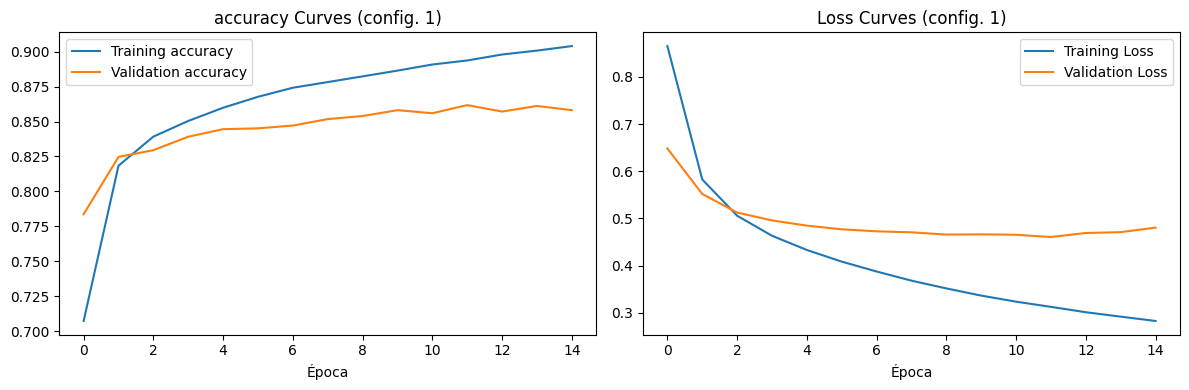

In [17]:
plot_learning_curve(history1, "(config. 1)")

In [18]:
model1 = tf.keras.models.load_model(RUTA_MODELO)   # mejor época según val_loss
loss, acc = model1.evaluate(test_ds, verbose=0)
print(f"Accuracy en prueba (config. 1): {acc:.4f}")
resultados.append({"Configuración": "1. Una capa oculta",
                   "Parámetros": model1.count_params(),
                   "Accuracy entrenamiento (máx.)": max(history1.history["accuracy"]),
                   "Accuracy validación (máx.)": max(history1.history["val_accuracy"]),
                   "Accuracy prueba": acc})

Accuracy en prueba (config. 1): 0.8608


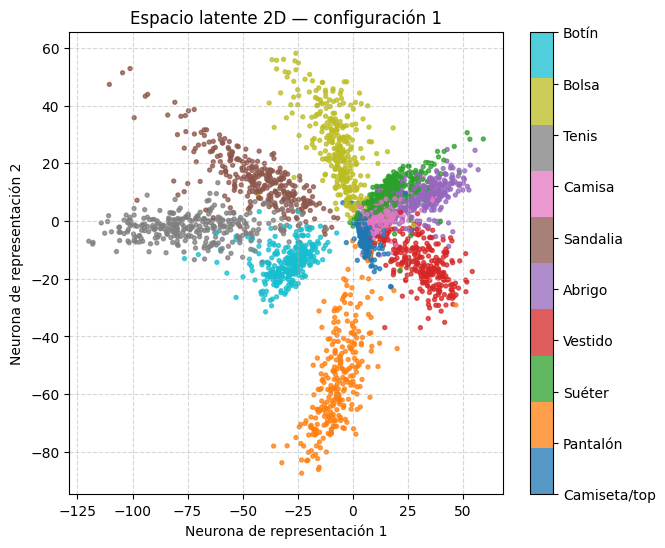

In [19]:
plot_espacio_2d(model1, "configuración 1")

## Configuración 2: Más profunda

Tres capas ocultas (256, 128, 64) antes de la capa 2D, para ver si más capacidad ayuda a separar las clases.

In [20]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 256, activation = "relu"),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])

model2.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,272 (946.38 KB)

 Trainable params: 242,272 (946.38 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
RUTA_MODELO = "models/config_2.keras"
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=RUTA_MODELO,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)

history2 = model2.fit(
    train_ds,
    epochs = EPOCAS,
    validation_data = val_ds,
    callbacks = [model_checkpoint],
    verbose = 2
)

Epoch 1/15
1875/1875 - 15s - 8ms/step - accuracy: 0.6606 - loss: 0.9562 - val_accuracy: 0.7917 - val_loss: 0.6667
Epoch 2/15
1875/1875 - 12s - 6ms/step - accuracy: 0.8173 - loss: 0.5856 - val_accuracy: 0.8289 - val_loss: 0.5786
Epoch 3/15
1875/1875 - 11s - 6ms/step - accuracy: 0.8523 - loss: 0.4877 - val_accuracy: 0.8448 - val_loss: 0.5290
Epoch 4/15
1875/1875 - 12s - 6ms/step - accuracy: 0.8658 - loss: 0.4365 - val_accuracy: 0.8630 - val_loss: 0.4976
Epoch 5/15
1875/1875 - 12s - 6ms/step - accuracy: 0.8741 - loss: 0.3992 - val_accuracy: 0.8682 - val_loss: 0.5023
Epoch 6/15
1875/1875 - 10s - 5ms/step - accuracy: 0.8798 - loss: 0.3735 - val_accuracy: 0.8698 - val_loss: 0.4718
Epoch 7/15
1875/1875 - 11s - 6ms/step - accuracy: 0.8859 - loss: 0.3529 - val_accuracy: 0.8696 - val_loss: 0.4982
Epoch 8/15
1875/1875 - 12s - 6ms/step - accuracy: 0.8888 - loss: 0.3432 - val_accuracy: 0.8754 - val_loss: 0.4843
Epoch 9/15
1875/1875 - 16s - 8ms/step - accuracy: 0.8943 - loss: 0.3206 - val_accuracy: 

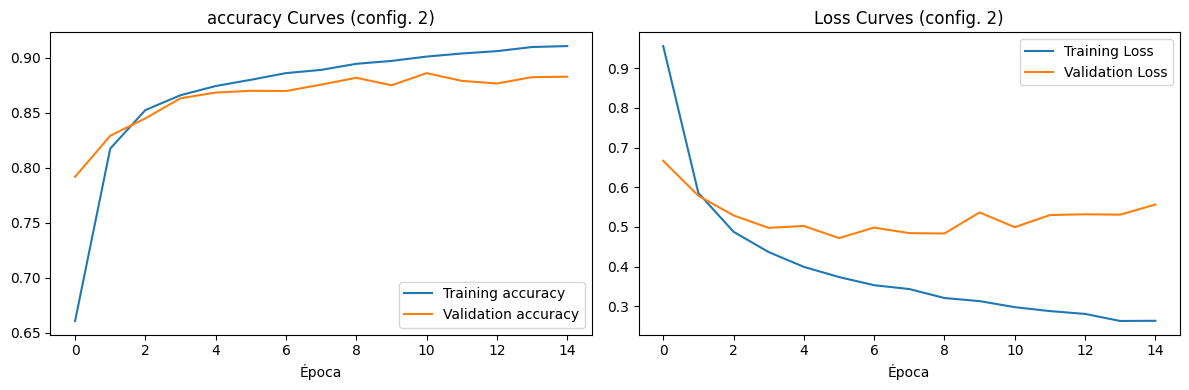

In [22]:
plot_learning_curve(history2, "(config. 2)")

In [23]:
model2 = tf.keras.models.load_model(RUTA_MODELO)   # mejor época según val_loss
loss, acc = model2.evaluate(test_ds, verbose=0)
print(f"Accuracy en prueba (config. 2): {acc:.4f}")
resultados.append({"Configuración": "2. Más profunda",
                   "Parámetros": model2.count_params(),
                   "Accuracy entrenamiento (máx.)": max(history2.history["accuracy"]),
                   "Accuracy validación (máx.)": max(history2.history["val_accuracy"]),
                   "Accuracy prueba": acc})

Accuracy en prueba (config. 2): 0.8630


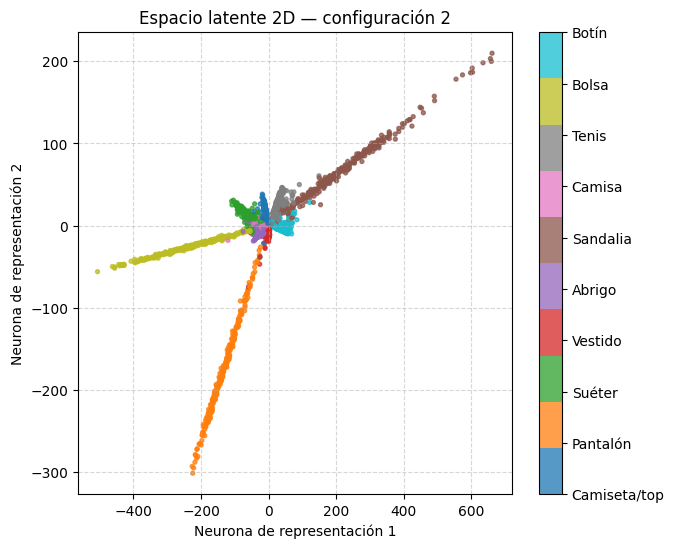

In [24]:
plot_espacio_2d(model2, "configuración 2")

## Configuración 3: Profunda con Dropout

Dos capas ocultas (256, 128) con `Dropout(0.3)` después de cada una, para reducir el sobreajuste.

In [25]:
model3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 256, activation = "relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])

model3.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 234,144 (914.62 KB)

 Trainable params: 234,144 (914.62 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
RUTA_MODELO = "models/config_3.keras"
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=RUTA_MODELO,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)

history3 = model3.fit(
    train_ds,
    epochs = EPOCAS,
    validation_data = val_ds,
    callbacks = [model_checkpoint],
    verbose = 2
)

Epoch 1/15


In [ ]:
plot_learning_curve(history3, "(config. 3)")

In [ ]:
model3 = tf.keras.models.load_model(RUTA_MODELO)   # mejor época según val_loss
loss, acc = model3.evaluate(test_ds, verbose=0)
print(f"Accuracy en prueba (config. 3): {acc:.4f}")
resultados.append({"Configuración": "3. Profunda con Dropout",
                   "Parámetros": model3.count_params(),
                   "Accuracy entrenamiento (máx.)": max(history3.history["accuracy"]),
                   "Accuracy validación (máx.)": max(history3.history["val_accuracy"]),
                   "Accuracy prueba": acc})

In [ ]:
plot_espacio_2d(model3, "configuración 3")

## Comparación de las configuraciones

In [ ]:
tabla = pd.DataFrame(resultados).set_index("Configuración")
tabla.style.format({"Accuracy entrenamiento (máx.)": "{:.4f}", "Accuracy validación (máx.)": "{:.4f}",
                    "Accuracy prueba": "{:.4f}", "Parámetros": "{:,}"})

In [ ]:
plt.figure(figsize=(7, 4))
barras = plt.bar(tabla.index, tabla["Accuracy prueba"], color=["#4C72B0", "#55A868", "#C44E52"])
plt.bar_label(barras, fmt="%.4f")
plt.ylim(0.7, 0.95)
plt.ylabel("Accuracy en prueba")
plt.title("Accuracy en prueba por configuración")
plt.xticks(rotation=10)
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))
for k, h in [("1", history1), ("2", history2), ("3", history3)]:
    plt.plot(h.history["val_accuracy"], label=f"Config. {k}")
plt.xlabel("Época")
plt.ylabel("Validation accuracy")
plt.title("Accuracy de validación por época")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Matriz de confusión del mejor modelo

In [ ]:
modelos = {"1": model1, "2": model2, "3": model3}
mejor = tabla["Accuracy prueba"].idxmax()
mejor_modelo = modelos[mejor.split(".")[0]]
print("Mejor configuración:", mejor)

probabilidades = mejor_modelo.predict(X_test, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=clases,
    cmap="Blues",
    ax=ax,
    xticks_rotation=45,
)
plt.title(f"Matriz de confusión en prueba (Fashion-MNIST) — config. {mejor.split('.')[0]}")
plt.grid(False)
plt.show()